# 04 - Cleaning and the 124 cells

Notebooks 02 and 03 found problems in the data. Here I decide what to do about each one, and get from 140 cells down to the 124 the paper uses.

The cell decisions come from the paper's own data loading notebook (`Load Data.ipynb` in the authors' repo, github.com/rdbraatz/data-driven-prediction-of-battery-cycle-life-before-capacity-degradation). I follow it so my results stay comparable to theirs, and I check each rule against the data.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.split import split_of

cells = pd.read_csv("../data/cells.csv")
cycles = pd.read_parquet("../data/cycles.parquet")
print(cells.shape, cycles.shape)

(140, 10) (114738, 9)


## Rule 1: merge the five continued cells

Batch 1 cells 0 to 4 kept cycling in batch 2. The batch 2 cycles get appended to the batch 1 cell, numbered after its last batch 1 cycle, and the cycle life becomes batch 1 life + number of batch 2 cycles. That is the same arithmetic as the paper (`add_len = [662, 981, 1060, 208, 482]`).

In [2]:
CONTINUED = {"b2c7": "b1c0", "b2c8": "b1c1", "b2c9": "b1c2", "b2c15": "b1c3", "b2c16": "b1c4"}

cells = cells.set_index("cell_id")
cells["cycle_life"] = cells["cycle_life_file"]

for b2, b1 in CONTINUED.items():
    offset = cells.loc[b1, "n_cycles"]
    rows = cycles["cell_id"] == b2
    cycles.loc[rows, "cycle"] += offset
    cycles.loc[rows, "cell_id"] = b1
    cells.loc[b1, "cycle_life"] = cells.loc[b1, "cycle_life_file"] + cells.loc[b2, "n_cycles"]
    print(f"{b2} -> {b1}: {cells.loc[b2, 'n_cycles']} cycles added, life {cells.loc[b1, 'cycle_life_file']:.0f} -> {cells.loc[b1, 'cycle_life']:.0f}")

b2c7 -> b1c0: 662 cycles added, life 1190 -> 1852
b2c8 -> b1c1: 981 cycles added, life 1179 -> 2160
b2c9 -> b1c2: 1060 cycles added, life 1177 -> 2237
b2c15 -> b1c3: 208 cycles added, life 1226 -> 1434
b2c16 -> b1c4: 482 cycles added, life 1227 -> 1709


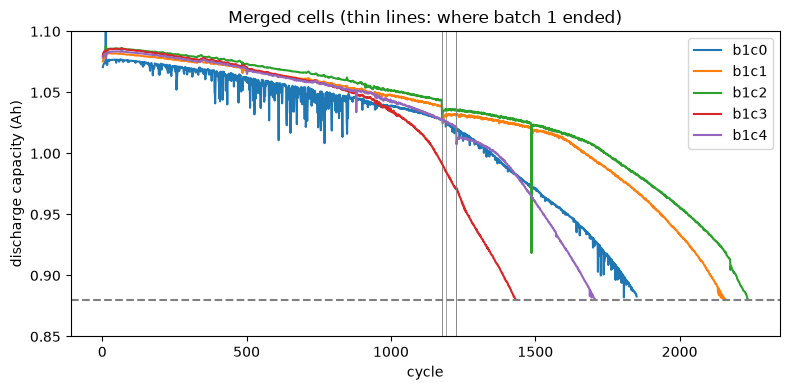

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for b1 in CONTINUED.values():
    d = cycles[(cycles["cell_id"] == b1) & (cycles["cycle"] > 1)]
    ax.plot(d["cycle"], d["q_discharge"], label=b1)
    ax.axvline(cells.loc[b1, "n_cycles"], color="grey", linewidth=0.5)
ax.axhline(0.88, color="grey", linestyle="--")
ax.set_ylim(0.85, 1.1)
ax.set_xlabel("cycle")
ax.set_ylabel("discharge capacity (Ah)")
ax.set_title("Merged cells (thin lines: where batch 1 ended)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/merged_cells.png", dpi=120)
plt.show()

## Rule 2: drop cells

| Cells | Reason |
|---|---|
| b2c7, b2c8, b2c9, b2c15, b2c16 | already merged into b1c0 to b1c4 |
| b1c8, b1c10, b1c12, b1c13, b1c22 | never reach 80% capacity, and they were not continued (notebook 02) |
| b3c23, b3c32 | no cycle life: still above 80% after 2,000+ cycles |
| b3c2, b3c37, b3c42, b3c43 | the paper calls them "noisy channels" |

In [4]:
DROP = {
    "merged into batch 1": list(CONTINUED.keys()),
    "never reached 80%": ["b1c8", "b1c10", "b1c12", "b1c13", "b1c22"],
    "no cycle life": ["b3c23", "b3c32"],
    "noisy channel (paper)": ["b3c2", "b3c37", "b3c42", "b3c43"],
}
dropped = [cell for ids in DROP.values() for cell in ids]
print(len(dropped), "cells dropped")

16 cells dropped


The noisy channel reason is the only one I can't see directly in notebook 02 or 03, so here is a check. Two simple noise measures for every batch 3 cell: how much the capacity jumps from one cycle to the next, and how rough the ΔQ curve between cycle 10 and 100 is.

In [5]:
from src.load import open_batch, n_cells, get_qdlin

f = open_batch(3, root="../")
rough = {}
for i in range(n_cells(f)):
    dq = get_qdlin(f, i, 100) - get_qdlin(f, i, 10)
    rough[f"b3c{i}"] = np.mean(np.abs(np.diff(dq, 2))) * 1e4
f.close()

b3 = cycles[cycles["cell_id"].str.startswith("b3") & (cycles["cycle"] > 1)]
jumps = b3.groupby("cell_id")["q_discharge"].apply(lambda q: np.std(np.diff(q.values)) * 1000)

noise = pd.DataFrame({"capacity_jumps": jumps, "dq_roughness": pd.Series(rough)})
noise["dropped_by_paper"] = noise.index.isin(DROP["noisy channel (paper)"] + DROP["no cycle life"])
noise.sort_values("dq_roughness", ascending=False).round(3).head(10)

,capacity_jumps,dq_roughness,dropped_by_paper
b3c37,2.770,2.583,True
b3c32,0.334,0.592,True
b3c36,0.348,0.193,False
b3c38,0.140,0.186,False
b3c33,0.222,0.185,False
b3c34,0.218,0.180,False
b3c39,0.254,0.172,False
b3c35,0.305,0.154,False
b3c20,0.383,0.102,False
b3c23,0.364,0.095,True


In [6]:
noise.groupby("dropped_by_paper")[["capacity_jumps", "dq_roughness"]].median().round(3)

,capacity_jumps,dq_roughness
dropped_by_paper,,
False,0.335,0.069
True,0.319,0.090


In [7]:
cells = cells.drop(index=dropped)
cycles = cycles[~cycles["cell_id"].isin(dropped)]
print(len(cells), "cells left")

124 cells left


## Rule 3: clean the cycle values

None of these remove whole cycles from the middle of a cell, so cycle numbers stay continuous. Bad values become NaN.

- batch 1 cycle 1 is all zeros: drop that row
- internal resistance of 0: meter dropout, set to NaN
- charge time over 60 minutes: test paused, set to NaN
- discharge capacity over 1.2 Ah: impossible for a 1.1 Ah cell, set to NaN
- cycles after the cycle life (batch 2 kept cycling): drop them

In [8]:
before = len(cycles)
cycles = cycles[~((cycles["cycle"] == 1) & (cycles["q_discharge"] == 0))].copy()
print("empty first cycles dropped:", before - len(cycles))

bad_ir = cycles["ir"] == 0
bad_ct = cycles["charge_time"] > 60
bad_q = cycles["q_discharge"] > 1.2
cycles.loc[bad_ir, "ir"] = np.nan
cycles.loc[bad_ct, "charge_time"] = np.nan
cycles.loc[bad_q, ["q_discharge", "q_charge"]] = np.nan
print("set to NaN: ir", bad_ir.sum(), "| charge_time", bad_ct.sum(), "| capacity", bad_q.sum())

life = cycles["cell_id"].map(cells["cycle_life"])
before = len(cycles)
cycles = cycles[cycles["cycle"] < life]
print("cycles after end of life dropped:", before - len(cycles))

empty first cycles dropped: 41
set to NaN: ir 21 | charge_time 14 | capacity 4
cycles after end of life dropped: 1222


## Rule 4: add the paper's split

In [9]:
cells["split"] = [split_of(cell) for cell in cells.index]
print(cells["split"].value_counts())
print("cells without a split:", cells["split"].isna().sum())

split
test_primary      43
train             41
test_secondary    40
Name: count, dtype: int64
cells without a split: 0


In [10]:
cells.groupby("split")["cycle_life"].describe()[["count", "min", "50%", "max"]]

,count,min,50%,max
split,,,,
test_primary,43.0,148.0,561.0,2237.0
test_secondary,40.0,541.0,964.5,1935.0
train,41.0,300.0,527.0,2160.0


## Final checks

Every cell should now end just above 0.88 Ah, and the cycle numbers should run without gaps.

In [11]:
last_q = cycles.sort_values("cycle").groupby("cell_id")["q_discharge"].last()
print("capacity at the last kept cycle: min", last_q.min().round(3), "max", last_q.max().round(3))
print(last_q.sort_values().head(3).round(3))
print(last_q.sort_values().tail(3).round(3))

gaps = cycles.groupby("cell_id")["cycle"].apply(lambda x: (x.diff().dropna() != 1).sum())
print("cells with gaps:", (gaps > 0).sum())
print("cells:", cycles["cell_id"].nunique(), "| rows:", len(cycles))

capacity at the last kept cycle: min 0.88 max 0.885
cell_id
b1c1     0.88
b3c38    0.88
b3c4     0.88
Name: q_discharge, dtype: float64
cell_id
b1c17    0.883
b1c37    0.883
b2c46    0.885
Name: q_discharge, dtype: float64
cells with gaps: 0
cells: 124 | rows: 99238


## Save

In [12]:
cells = cells.reset_index()[["cell_id", "batch", "policy", "cycle_life", "split"]]
cells.to_csv("../data/cells_clean.csv", index=False)
cycles.to_parquet("../data/cycles_clean.parquet", index=False)
print("saved", len(cells), "cells and", len(cycles), "cycles")

saved 124 cells and 99238 cycles


## Notes

- 124 cells: train 41, primary test 43, secondary test 40. Same as the paper.
- The merged cells join up cleanly. Each one has a small step up where batch 2 starts (the cell rested between the two runs and got a bit of capacity back), then keeps fading. Their lives go up a lot: b1c2 goes from 1,177 to 2,237 cycles. Without the merge, five of the longest-lived cells would get a much too short label.
- The noisy channel rule only partly shows up in my checks. b3c37 is clearly noisy in both measures (about 8 times the capacity jumps of a normal cell), and b3c32 has a rough ΔQ curve. b3c2, b3c42 and b3c43 look normal in both, so whatever was wrong with them isn't visible in the summary or the ΔQ curve. I still drop them so my numbers can be compared with the paper's, but this is the one rule I'm taking on trust.
- Cleaning the cycle values: 41 empty first cycles dropped, 21 resistance values, 14 charge times and 4 capacities set to NaN, and 1,222 cycles after end of life dropped (almost all from batch 2). 99,238 cycle rows remain.
- Every cell now ends between 0.880 and 0.885 Ah, and no cell has gaps in its cycle numbers.
- b2c1 is in the primary test set with a life of only 148 cycles, far below any training cell (shortest 300). BatteryML drops it from the test set because models do badly on it. I keep it, like the paper, but I'll report the test error with and without it.
- The secondary test set lives longer (median 965 cycles against 527 to 561 in the others). A model trained on batches 1 and 2 has rarely seen cells that long, which is one more reason to expect a higher error there.